# Behavioral EDA: Investigating Pre-Abuse Patterns

The initial exploratory analysis showed that users with an upcoming abuse episode were more active on average, with the largest difference appearing in offline coupon redemptions. However, averages alone can be misleading because user activity is highly right-skewed.

This section investigates these patterns more carefully. The goals are to determine:

- whether differences exist throughout the distribution or are driven by extreme users,
- whether users change their behavior shortly before an abuse episode,
- whether behavioral rates and composition are more informative than raw counts,
- and whether observed relationships remain consistent over time.

Only observations from the training period are used so that validation and test periods remain untouched during exploratory feature development.

In [ ]:
from google.cloud import bigquery
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import mannwhitneyu, ttest_ind, ttest_1samp, wilcoxon
from sklearn.metrics import roc_auc_score, average_precision_score

PROJECT_ID = "alibaba-promo-abuse-1790454859"

client = bigquery.Client(project=PROJECT_ID)


def query_df(sql):
    return (
        client.query(sql)
        .result()
        .to_dataframe(
            create_bqstorage_client=False
        )
    )


TRAIN_START = "2016-02-01"
TRAIN_END = "2016-04-25"

# 1. Scoring Population Over Time

Goal: understand how the number and baseline activity
of eligible users changes across weekly prediction dates.

In [2]:
population_weekly = query_df(
    f"""
    SELECT
        prediction_date,
        COUNT(*) AS eligible_users,
        AVG(
            eligibility_event_count_30d
        ) AS avg_events_30d,
        AVG(
            eligibility_coupon_receipts_30d
        ) AS avg_coupon_receipts_30d

    FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

    WHERE prediction_date BETWEEN
        DATE '{TRAIN_START}'
        AND DATE '{TRAIN_END}'

    GROUP BY prediction_date
    ORDER BY prediction_date
    """
)

population_weekly

,prediction_date,eligible_users,avg_events_30d,avg_coupon_receipts_30d
0,2016-02-01,48922,11.510057,4.181493
1,2016-02-08,51224,11.151062,4.508765
2,2016-02-15,46697,10.759449,4.853631
3,2016-02-22,42966,10.502514,5.116138
4,2016-02-29,22831,12.986334,3.879331
5,2016-03-07,22496,14.757646,3.482175
6,2016-03-14,26773,15.375266,3.306802
7,2016-03-21,27441,15.545789,3.197588
8,2016-03-28,38466,13.891515,3.042323
9,2016-04-04,39349,13.503062,2.980279


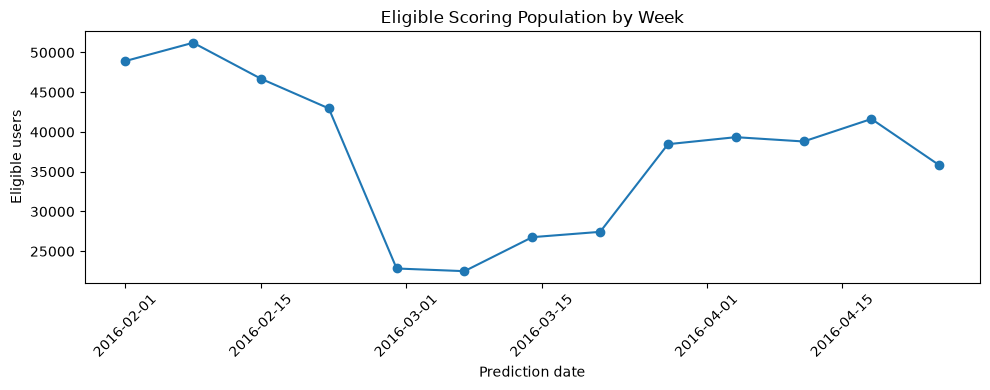

In [3]:
plt.figure(figsize=(10, 4))

plt.plot(
    population_weekly["prediction_date"],
    population_weekly["eligible_users"],
    marker="o",
)

plt.xlabel("Prediction date")
plt.ylabel("Eligible users")
plt.title("Eligible Scoring Population by Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Baseline Activity Distribution

Goal: understand how heterogeneous the eligible population
is before examining abuse outcomes.

In [4]:
activity_distribution = query_df(
    f"""
    SELECT

        APPROX_QUANTILES(
            eligibility_event_count_30d,
            100
        )[OFFSET(25)] AS events_p25,

        APPROX_QUANTILES(
            eligibility_event_count_30d,
            100
        )[OFFSET(50)] AS events_median,

        APPROX_QUANTILES(
            eligibility_event_count_30d,
            100
        )[OFFSET(75)] AS events_p75,

        APPROX_QUANTILES(
            eligibility_event_count_30d,
            100
        )[OFFSET(90)] AS events_p90,

        APPROX_QUANTILES(
            eligibility_event_count_30d,
            100
        )[OFFSET(99)] AS events_p99,

        APPROX_QUANTILES(
            eligibility_coupon_receipts_30d,
            100
        )[OFFSET(25)] AS receipts_p25,

        APPROX_QUANTILES(
            eligibility_coupon_receipts_30d,
            100
        )[OFFSET(50)] AS receipts_median,

        APPROX_QUANTILES(
            eligibility_coupon_receipts_30d,
            100
        )[OFFSET(75)] AS receipts_p75,

        APPROX_QUANTILES(
            eligibility_coupon_receipts_30d,
            100
        )[OFFSET(90)] AS receipts_p90,

        APPROX_QUANTILES(
            eligibility_coupon_receipts_30d,
            100
        )[OFFSET(99)] AS receipts_p99

    FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

    WHERE prediction_date BETWEEN
        DATE '{TRAIN_START}'
        AND DATE '{TRAIN_END}'
    """
)

activity_distribution.T

,0
events_p25,6
events_median,8
events_p75,13
events_p90,24
events_p99,77
receipts_p25,1
receipts_median,3
receipts_p75,5
receipts_p90,8
receipts_p99,16


# 3. Future Abuse Outcome

A positive observation means that an abuse episode overlaps
the 7-day period beginning at the prediction date.

Only training-period prediction dates are examined here.

In [5]:
label_distribution = query_df(
    f"""
    WITH population AS (

        SELECT
            user_id,
            prediction_date

        FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

        WHERE prediction_date BETWEEN
            DATE '{TRAIN_START}'
            AND DATE '{TRAIN_END}'

    ),

    labeled AS (

        SELECT

            p.user_id,
            p.prediction_date,

            MAX(
                CASE
                    WHEN a.user_id IS NOT NULL
                    THEN 1
                    ELSE 0
                END
            ) AS abuse_next_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_staging.stg_abuse_cases` a

            ON p.user_id = a.user_id

            AND a.abuse_start_date
                < DATE_ADD(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )

            AND a.abuse_end_date
                >= p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date

    )

    SELECT

        prediction_date,

        COUNT(*) AS eligible_users,

        SUM(abuse_next_7d)
            AS positive_cases,

        SAFE_DIVIDE(
            SUM(abuse_next_7d),
            COUNT(*)
        ) AS positive_rate

    FROM labeled

    GROUP BY prediction_date
    ORDER BY prediction_date
    """
)

label_distribution

,prediction_date,eligible_users,positive_cases,positive_rate
0,2016-02-01,48922,586,0.011978
1,2016-02-08,51224,607,0.011850
2,2016-02-15,46697,546,0.011692
3,2016-02-22,42966,494,0.011497
4,2016-02-29,22831,247,0.010819
5,2016-03-07,22496,246,0.010935
6,2016-03-14,26773,300,0.011205
7,2016-03-21,27441,310,0.011297
8,2016-03-28,38466,444,0.011543
9,2016-04-04,39349,452,0.011487


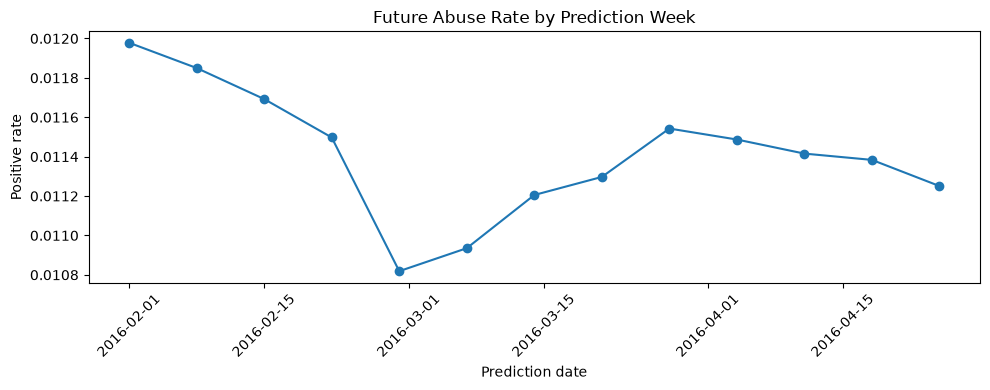

In [6]:
plt.figure(figsize=(10, 4))

plt.plot(
    label_distribution["prediction_date"],
    label_distribution["positive_rate"],
    marker="o",
)

plt.xlabel("Prediction date")
plt.ylabel("Positive rate")
plt.title("Future Abuse Rate by Prediction Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Behavioral Comparison

Goal: Before an abuse episode happens, are those users simply more active, or is their type of activity different?

In [7]:
behavior_by_label = query_df(
    f"""
    WITH population AS (

        SELECT
            user_id,
            prediction_date

        FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

        WHERE prediction_date BETWEEN
            DATE '{TRAIN_START}'
            AND DATE '{TRAIN_END}'

    ),

    labels AS (

        SELECT

            p.user_id,
            p.prediction_date,

            MAX(
                CASE
                    WHEN a.user_id IS NOT NULL
                    THEN 1
                    ELSE 0
                END
            ) AS abuse_next_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_staging.stg_abuse_cases` a

            ON p.user_id = a.user_id

            AND a.abuse_start_date
                < DATE_ADD(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )

            AND a.abuse_end_date
                >= p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date

    ),

    offline AS (

        SELECT

            p.user_id,
            p.prediction_date,

            COALESCE(
                SUM(d.total_events),
                0
            ) AS offline_events,

            COALESCE(
                SUM(d.coupon_receipts),
                0
            ) AS offline_coupon_receipts,

            COALESCE(
                SUM(d.purchases),
                0
            ) AS offline_purchases,

            COALESCE(
                SUM(d.coupon_redemptions),
                0
            ) AS offline_coupon_redemptions

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_daily.offline_user_daily` d

            ON p.user_id = d.user_id

            AND d.activity_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )

            AND d.activity_date < p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date

    ),

    online AS (

        SELECT

            p.user_id,
            p.prediction_date,

            COALESCE(
                SUM(d.total_events),
                0
            ) AS online_events,

            COALESCE(
                SUM(d.clicks),
                0
            ) AS online_clicks,

            COALESCE(
                SUM(d.purchases),
                0
            ) AS online_purchases,

            COALESCE(
                SUM(d.coupon_receipts),
                0
            ) AS online_coupon_receipts

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_daily.online_user_daily` d

            ON p.user_id = d.user_id

            AND d.activity_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )

            AND d.activity_date < p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date

    ),

    combined AS (

        SELECT

            l.abuse_next_7d,

            o.offline_events,
            o.offline_coupon_receipts,
            o.offline_purchases,
            o.offline_coupon_redemptions,

            n.online_events,
            n.online_clicks,
            n.online_purchases,
            n.online_coupon_receipts

        FROM labels l

        JOIN offline o
          USING (
              user_id,
              prediction_date
          )

        JOIN online n
          USING (
              user_id,
              prediction_date
          )

    )

    SELECT

        abuse_next_7d,

        COUNT(*) AS observations,

        AVG(offline_events)
            AS avg_offline_events,

        AVG(offline_coupon_receipts)
            AS avg_offline_coupon_receipts,

        AVG(offline_purchases)
            AS avg_offline_purchases,

        AVG(offline_coupon_redemptions)
            AS avg_offline_coupon_redemptions,

        AVG(online_events)
            AS avg_online_events,

        AVG(online_clicks)
            AS avg_online_clicks,

        AVG(online_purchases)
            AS avg_online_purchases,

        AVG(online_coupon_receipts)
            AS avg_online_coupon_receipts

    FROM combined

    GROUP BY abuse_next_7d
    ORDER BY abuse_next_7d
    """
)

behavior_by_label.T

,0,1
abuse_next_7d,0,1
observations,477879,5552
avg_offline_events,3.059567,4.579251
avg_offline_coupon_receipts,2.02677,3.065562
avg_offline_purchases,1.032797,1.513689
avg_offline_coupon_redemptions,0.31666,0.833754
avg_online_events,9.645561,11.955512
avg_online_clicks,6.642426,8.465058
avg_online_purchases,1.302568,1.456232
avg_online_coupon_receipts,1.700566,2.034222


## Second-Pass Behavioral EDA

The initial EDA showed higher activity among future-abuse users, especially for offline coupon redemptions.

This pass examines:
- distribution differences,
- recent activity changes,
- behavioral rates,
- and stability over time.

Only training-period data is used.

In [22]:
eda_base = query_df(
    f"""
    WITH population AS (

        SELECT
            user_id,
            prediction_date

        FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

        WHERE prediction_date BETWEEN
            DATE '{TRAIN_START}'
            AND DATE '{TRAIN_END}'
    ),

    labels AS (

        SELECT
            p.user_id,
            p.prediction_date,

            MAX(
                CASE
                    WHEN a.user_id IS NOT NULL
                    THEN 1
                    ELSE 0
                END
            ) AS abuse_next_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_staging.stg_abuse_cases` a
            ON p.user_id = a.user_id
            AND a.abuse_start_date
                < DATE_ADD(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )
            AND a.abuse_end_date
                >= p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    ),

    offline AS (

        SELECT
            p.user_id,
            p.prediction_date,

            COALESCE(SUM(d.total_events), 0)
                AS offline_events_30d,

            COALESCE(SUM(d.coupon_receipts), 0)
                AS offline_coupon_receipts_30d,

            COALESCE(SUM(d.purchases), 0)
                AS offline_purchases_30d,

            COALESCE(SUM(d.coupon_redemptions), 0)
                AS offline_redemptions_30d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.total_events
                        ELSE 0
                    END
                ),
                0
            ) AS offline_events_7d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.coupon_receipts
                        ELSE 0
                    END
                ),
                0
            ) AS offline_coupon_receipts_7d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.purchases
                        ELSE 0
                    END
                ),
                0
            ) AS offline_purchases_7d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.coupon_redemptions
                        ELSE 0
                    END
                ),
                0
            ) AS offline_redemptions_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_daily.offline_user_daily` d
            ON p.user_id = d.user_id
            AND d.activity_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )
            AND d.activity_date < p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    ),

    online AS (

        SELECT
            p.user_id,
            p.prediction_date,

            COALESCE(SUM(d.total_events), 0)
                AS online_events_30d,

            COALESCE(SUM(d.clicks), 0)
                AS online_clicks_30d,

            COALESCE(SUM(d.purchases), 0)
                AS online_purchases_30d,

            COALESCE(SUM(d.coupon_receipts), 0)
                AS online_coupon_receipts_30d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.total_events
                        ELSE 0
                    END
                ),
                0
            ) AS online_events_7d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.clicks
                        ELSE 0
                    END
                ),
                0
            ) AS online_clicks_7d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.purchases
                        ELSE 0
                    END
                ),
                0
            ) AS online_purchases_7d,

            COALESCE(
                SUM(
                    CASE
                        WHEN d.activity_date >= DATE_SUB(
                            p.prediction_date,
                            INTERVAL 7 DAY
                        )
                        THEN d.coupon_receipts
                        ELSE 0
                    END
                ),
                0
            ) AS online_coupon_receipts_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_daily.online_user_daily` d
            ON p.user_id = d.user_id
            AND d.activity_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )
            AND d.activity_date < p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    )

    SELECT
        l.*,
        o.* EXCEPT(user_id, prediction_date),
        n.* EXCEPT(user_id, prediction_date)

    FROM labels l

    LEFT JOIN offline o
        USING(user_id, prediction_date)

    LEFT JOIN online n
        USING(user_id, prediction_date)
    """
)

eda_base.shape

(483431, 19)

### Behavioral Distribution Differences

Compare percentiles between future-abuse and non-abuse users to see whether differences are broad or driven mainly by extreme users.

In [23]:
variables = [
    "offline_events_30d",
    "offline_coupon_receipts_30d",
    "offline_purchases_30d",
    "offline_redemptions_30d",
    "online_events_30d",
    "online_clicks_30d",
    "online_purchases_30d",
    "online_coupon_receipts_30d",
]

quantiles = (
    eda_base
    .groupby("abuse_next_7d")[variables]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.99])
)

quantiles

offline_events_30d  offline_coupon_receipts_30d  \
abuse_next_7d                                                         
0             0.25                 0.0                          0.0   
              0.50                 1.0                          1.0   
              0.75                 5.0                          3.0   
              0.90                 8.0                          6.0   
              0.99                22.0                         13.0   
1             0.25                 0.0                          0.0   
              0.50                 3.0                          2.0   
              0.75                 8.0                          5.0   
              0.90                12.0                          8.0   
              0.99                19.0                         14.0   

                    offline_purchases_30d  offline_redemptions_30d  \
abuse_next_7d                                                        
0             0.25                    0.0                      0.0   
              0.50                    0.0                      0.0   
              0.75                    1.0                      0.0   
              0.90                    4.0                      1.0   
              0.99                   11.0                      8.0   
1             0.25                    0.0                      0.0   
              0.50                    0.0                      0.0   
              0.75                    2.0                      2.0   
              0.90                    5.0                      3.0   
              0.99                   10.0                      4.0   

                    online_events_30d  online_clicks_30d  \
abuse_next_7d                                              
0             0.25                0.0                0.0   
              0.50                6.0                1.0   
              0.75               11.0                7.0   
              0.90               22.0               17.0   
              0.99               76.0               69.0   
1             0.25                4.0                1.0   
              0.50                9.0                4.0   
              0.75               14.0                9.0   
              0.90               23.0               19.0   
              0.99              75.49               68.0   

                    online_purchases_30d  online_coupon_receipts_30d  
abuse_next_7d                                                         
0             0.25                   0.0                         0.0  
              0.50                   0.0                         1.0  
              0.75                   2.0                         2.0  
              0.90                   4.0                         5.0  
              0.99                  12.0                        12.0  
1             0.25                   0.0                         0.0  
              0.50                   0.0                         1.0  
              0.75                   2.0                         3.0  
              0.90                   4.0                         5.0  
              0.99                  12.0                        11.0

### Recent Activity Acceleration

Compare the most recent 7 days with the prior 23 days to see whether users become more active shortly before an abuse episode.

In [24]:
eda_base["total_events_30d"] = (
    eda_base["offline_events_30d"]
    + eda_base["online_events_30d"]
)

eda_base["total_events_7d"] = (
    eda_base["offline_events_7d"]
    + eda_base["online_events_7d"]
)

eda_base["events_prior_23d"] = (
    eda_base["total_events_30d"]
    - eda_base["total_events_7d"]
)

eda_base["events_per_day_recent_7d"] = (
    eda_base["total_events_7d"] / 7
)

eda_base["events_per_day_prior_23d"] = (
    eda_base["events_prior_23d"] / 23
)

eda_base["activity_acceleration"] = (
    eda_base["events_per_day_recent_7d"]
    - eda_base["events_per_day_prior_23d"]
)

eda_base.groupby(
    "abuse_next_7d"
)[
    [
        "events_per_day_recent_7d",
        "events_per_day_prior_23d",
        "activity_acceleration",
    ]
].agg(
    ["mean", "median"]
)

events_per_day_recent_7d           events_per_day_prior_23d  \
                                  mean    median                     mean   
abuse_next_7d                                                               
0                             0.405607  0.142857                 0.428951   
1                             0.674969  0.428571                 0.513477   

                        activity_acceleration            
                 median                  mean    median  
abuse_next_7d                                            
0               0.26087             -0.023344 -0.217391  
1              0.391304              0.161492  0.037267

In [25]:
neg = eda_base.loc[
    eda_base["abuse_next_7d"] == 0,
    "activity_acceleration"
]

pos = eda_base.loc[
    eda_base["abuse_next_7d"] == 1,
    "activity_acceleration"
]

# Welch's t-test
t_stat, t_p = ttest_ind(
    pos,
    neg,
    equal_var=False,
)

# Mann-Whitney U
u_stat, u_p = mannwhitneyu(
    pos,
    neg,
    alternative="two-sided",
)

print("Welch t-test p-value:", t_p)
print("Mann-Whitney p-value:", u_p)

Welch t-test p-value: 4.78821875316552e-49
Mann-Whitney p-value: 3.1118938186655467e-214


In [26]:
mean_diff = pos.mean() - neg.mean()

pooled_sd = np.sqrt(
    (
        (len(pos) - 1) * pos.var(ddof=1)
        + (len(neg) - 1) * neg.var(ddof=1)
    )
    / (
        len(pos)
        + len(neg)
        - 2
    )
)

cohens_d = mean_diff / pooled_sd

print("Mean difference:", mean_diff)
print("Cohen's d:", cohens_d)

Mean difference: 0.1848358697066539
Cohen's d: 0.17581855208983446


In [27]:
y = eda_base["abuse_next_7d"]
x = eda_base["activity_acceleration"]

print(
    "ROC-AUC:",
    roc_auc_score(y, x)
)

print(
    "PR-AUC:",
    average_precision_score(y, x)
)

ROC-AUC: 0.6215950438070752
PR-AUC: 0.015905252996332095


In [28]:
for label, name in [
    (0, "Non-abuse"),
    (1, "Future abuse"),
]:

    values = (
        eda_base.loc[
            eda_base["abuse_next_7d"] == label,
            "activity_acceleration",
        ]
        .dropna()
    )

    t_stat, t_p = ttest_1samp(
        values,
        popmean=0,
    )

    w_stat, w_p = wilcoxon(
        values,
        alternative="two-sided",
    )

    print(f"\n{name}")
    print(f"N: {len(values):,}")
    print(f"Mean acceleration: {values.mean():.4f}")
    print(f"Median acceleration: {values.median():.4f}")
    print(f"One-sample t-test p-value: {t_p}")
    print(f"Wilcoxon p-value: {w_p}")


Non-abuse
N: 477,879
Mean acceleration: -0.0233
Median acceleration: -0.2174
One-sample t-test p-value: 5.013965283832513e-53
Wilcoxon p-value: 0.0

Future abuse
N: 5,552
Mean acceleration: 0.1615
Median acceleration: 0.0373
One-sample t-test p-value: 1.5279215984474973e-38
Wilcoxon p-value: 2.4814492148635186e-41


In [29]:
for label, name in [
    (0, "Non-abuse"),
    (1, "Future abuse"),
]:

    values = (
        eda_base.loc[
            eda_base["abuse_next_7d"] == label,
            "activity_acceleration",
        ]
        .dropna()
    )

    effect_size = (
        values.mean()
        / values.std(ddof=1)
    )

    print(
        name,
        "Cohen's d vs 0:",
        round(effect_size, 4),
    )

Non-abuse Cohen's d vs 0: -0.0222
Future abuse Cohen's d vs 0: 0.1756


### Behavioral Rates and Composition

Normalize raw counts using redemption rates, purchase-per-click rates, and coupon share to separate general activity from coupon-focused behavior.

In [30]:
eda_base["offline_redemption_rate_30d"] = np.where(
    eda_base["offline_coupon_receipts_30d"] > 0,
    eda_base["offline_redemptions_30d"]
    / eda_base["offline_coupon_receipts_30d"],
    np.nan,
)

eda_base["online_purchase_per_click_30d"] = np.where(
    eda_base["online_clicks_30d"] > 0,
    eda_base["online_purchases_30d"]
    / eda_base["online_clicks_30d"],
    np.nan,
)

eda_base["total_coupon_receipts_30d"] = (
    eda_base["offline_coupon_receipts_30d"]
    + eda_base["online_coupon_receipts_30d"]
)

eda_base["coupon_event_share_30d"] = (
    eda_base["total_coupon_receipts_30d"]
    / eda_base["total_events_30d"]
)

eda_base.groupby(
    "abuse_next_7d"
)[
    [
        "offline_redemption_rate_30d",
        "online_purchase_per_click_30d",
        "coupon_event_share_30d",
    ]
].agg(
    ["mean", "median"]
)

offline_redemption_rate_30d         \
                                     mean median   
abuse_next_7d                                      
0                                0.155291   0.00   
1                                0.302328   0.25   

              online_purchase_per_click_30d           coupon_event_share_30d  \
                                       mean    median                   mean   
abuse_next_7d                                                                  
0                                  0.243574  0.000000               0.421653   
1                                  0.438814  0.083333               0.390561   

                         
                 median  
abuse_next_7d            
0              0.333333  
1              0.333333

In [31]:
neg = eda_base.loc[
    eda_base["abuse_next_7d"] == 0,
    "activity_acceleration"
]

pos = eda_base.loc[
    eda_base["abuse_next_7d"] == 1,
    "activity_acceleration"
]

# Welch's t-test
t_stat, t_p = ttest_ind(
    pos,
    neg,
    equal_var=False,
)

# Mann-Whitney U
u_stat, u_p = mannwhitneyu(
    pos,
    neg,
    alternative="two-sided",
)

print("Welch t-test p-value:", t_p)
print("Mann-Whitney p-value:", u_p)

Welch t-test p-value: 4.78821875316552e-49
Mann-Whitney p-value: 3.1118938186655467e-214


### Temporal Stability

Check whether the main behavioral differences remain consistent across prediction weeks rather than appearing only during short periods.

In [32]:
weekly_behavior = (
    eda_base
    .groupby(
        [
            "prediction_date",
            "abuse_next_7d",
        ]
    )
    .agg(
        avg_offline_redemptions=(
            "offline_redemptions_30d",
            "mean",
        ),
        avg_offline_receipts=(
            "offline_coupon_receipts_30d",
            "mean",
        ),
        avg_total_events=(
            "total_events_30d",
            "mean",
        ),
        avg_activity_acceleration=(
            "activity_acceleration",
            "mean",
        ),
    )
    .reset_index()
)

weekly_behavior

,prediction_date,abuse_next_7d,avg_offline_redemptions,avg_offline_receipts,avg_total_events,avg_activity_acceleration
0,2016-02-01,0,0.091423,3.160439,11.430569,0.219957
1,2016-02-01,1,0.84471,4.518771,18.066553,0.412323
2,2016-02-08,0,0.199854,3.55426,11.099196,-0.237069
3,2016-02-08,1,0.960461,4.807249,15.476112,-0.067822
4,2016-02-15,0,0.315226,3.913068,10.717926,-0.275939
5,2016-02-15,1,1.122711,5.382784,14.269231,-0.080848
6,2016-02-22,0,0.425127,4.229704,10.461622,-0.078822
7,2016-02-22,1,1.103239,5.748988,14.018219,0.13774
8,2016-02-29,0,0.775106,2.093783,12.939515,0.138365
9,2016-02-29,1,0.8583,2.603239,17.267206,0.339352


### Offline Redemptions Over Time

Plot average offline coupon redemptions for positive and negative users across weeks to see whether the gap is persistent.

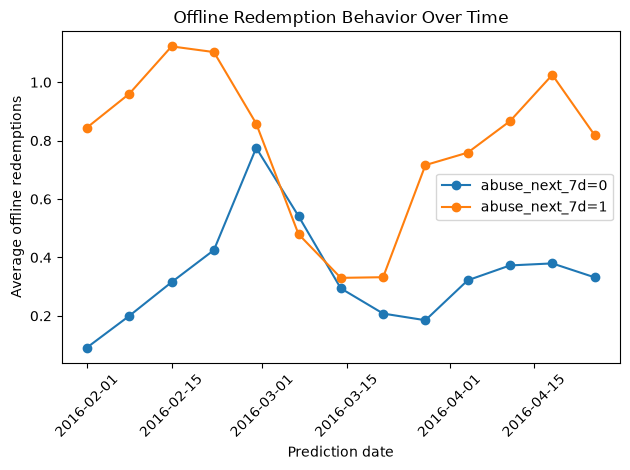

In [33]:
for label in [0, 1]:

    subset = weekly_behavior[
        weekly_behavior["abuse_next_7d"] == label
    ]

    plt.plot(
        subset["prediction_date"],
        subset["avg_offline_redemptions"],
        marker="o",
        label=f"abuse_next_7d={label}",
    )

plt.xlabel("Prediction date")
plt.ylabel("Average offline redemptions")
plt.title("Offline Redemption Behavior Over Time")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Behavior-Specific Acceleration

Overall activity accelerated before future abuse. We now separate this change by behavior to identify which activities are driving the pattern.

In [35]:
behavior_accel = eda_base.copy()

behaviors = {
    "offline_receipts": (
        "offline_coupon_receipts_30d",
        "offline_coupon_receipts_7d",
    ),
    "offline_purchases": (
        "offline_purchases_30d",
        "offline_purchases_7d",
    ),
    "offline_redemptions": (
        "offline_redemptions_30d",
        "offline_redemptions_7d",
    ),
    "online_clicks": (
        "online_clicks_30d",
        "online_clicks_7d",
    ),
    "online_purchases": (
        "online_purchases_30d",
        "online_purchases_7d",
    ),
    "online_receipts": (
        "online_coupon_receipts_30d",
        "online_coupon_receipts_7d",
    ),
}

for name, (col_30d, col_7d) in behaviors.items():

    behavior_accel[f"{name}_recent_rate"] = (
        behavior_accel[col_7d] / 7
    )

    behavior_accel[f"{name}_prior_rate"] = (
        (
            behavior_accel[col_30d]
            - behavior_accel[col_7d]
        )
        / 23
    )

    behavior_accel[f"{name}_acceleration"] = (
        behavior_accel[f"{name}_recent_rate"]
        - behavior_accel[f"{name}_prior_rate"]
    )

### Acceleration by Outcome

Compare the average and median acceleration of each behavior between future-abuse and non-abuse observations.

In [36]:
accel_cols = [
    f"{name}_acceleration"
    for name in behaviors
]

acceleration_summary = (
    behavior_accel
    .groupby("abuse_next_7d")[accel_cols]
    .agg(["mean", "median"])
)

acceleration_summary

offline_receipts_acceleration         \
                                       mean median   
abuse_next_7d                                        
0                                 -0.009759    0.0   
1                                  0.029523    0.0   

              offline_purchases_acceleration         \
                                        mean median   
abuse_next_7d                                         
0                                   0.001299    0.0   
1                                   0.039303    0.0   

              offline_redemptions_acceleration         \
                                          mean median   
abuse_next_7d                                           
0                                     0.001925    0.0   
1                                     0.040674    0.0   

              online_clicks_acceleration        online_purchases_acceleration  \
                                    mean median                          mean   
abuse_next_7d                                                                   
0                              -0.014272    0.0                     -0.001761   
1                               0.074635    0.0                       0.00636   

                     online_receipts_acceleration         
              median                         mean median  
abuse_next_7d                                             
0                0.0                     0.001149    0.0  
1                0.0                     0.011671    0.0

### Strength of Behavior-Specific Acceleration

Compare standardized effect sizes and standalone ROC-AUC to determine which acceleration signals distinguish future-abuse observations most strongly.

In [ ]:
results = []

for name in behaviors:

    col = f"{name}_acceleration"

    neg = behavior_accel.loc[
        behavior_accel["abuse_next_7d"] == 0,
        col
    ]

    pos = behavior_accel.loc[
        behavior_accel["abuse_next_7d"] == 1,
        col
    ]

    pooled_sd = np.sqrt(
        (
            (len(pos) - 1) * pos.var(ddof=1)
            + (len(neg) - 1) * neg.var(ddof=1)
        )
        / (len(pos) + len(neg) - 2)
    )

    cohens_d = (
        (pos.mean() - neg.mean()) / pooled_sd
        if pooled_sd > 0
        else np.nan
    )

    auc = roc_auc_score(
        behavior_accel["abuse_next_7d"],
        behavior_accel[col]
    )

    results.append({
        "behavior": name,
        "non_abuse_mean": neg.mean(),
        "future_abuse_mean": pos.mean(),
        "cohens_d": cohens_d,
        "roc_auc": auc
    })

acceleration_strength = (
    pd.DataFrame(results)
    .sort_values("roc_auc", ascending=False)
)

acceleration_strength

,behavior,non_abuse_mean,future_abuse_mean,cohens_d,roc_auc
3,online_clicks,-0.014272,0.074635,0.102089,0.606420
2,offline_redemptions,0.001925,0.040674,0.419705,0.591794
1,offline_purchases,0.001299,0.039303,0.312086,0.588390
0,offline_receipts,-0.009759,0.029523,0.167479,0.583895
5,online_receipts,0.001149,0.011671,0.054389,0.531717
4,online_purchases,-0.001761,0.006360,0.038515,0.516670


### Prevalence of Positive Acceleration

Because the median acceleration is zero for both groups, measure how often each behavior actually increases before the prediction date.

In [38]:
positive_acceleration_results = []

for name in behaviors:

    col = f"{name}_acceleration"

    shares = (
        behavior_accel
        .groupby("abuse_next_7d")[col]
        .apply(lambda x: (x > 0).mean())
    )

    positive_acceleration_results.append({
        "behavior": name,
        "non_abuse_positive_share": shares.loc[0],
        "future_abuse_positive_share": shares.loc[1],
        "difference": shares.loc[1] - shares.loc[0],
    })

positive_acceleration_share = (
    pd.DataFrame(positive_acceleration_results)
    .sort_values("difference", ascending=False)
)

positive_acceleration_share

,behavior,non_abuse_positive_share,future_abuse_positive_share,difference
3,online_clicks,0.169352,0.454971,0.285619
2,offline_redemptions,0.041393,0.290886,0.249493
1,offline_purchases,0.116889,0.313941,0.197052
0,offline_receipts,0.139533,0.297370,0.157837
5,online_receipts,0.170378,0.272154,0.101776
4,online_purchases,0.108354,0.179215,0.070861


## Recency and Burstiness

Behavior-specific acceleration showed the strongest differences in online clicks, offline redemptions, and offline purchases.

Next, examine whether these behaviors occur more recently and whether activity is concentrated into short bursts before the prediction date.

In [39]:
recency_burst = query_df(
    f"""
    WITH population AS (

        SELECT
            user_id,
            prediction_date

        FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

        WHERE prediction_date BETWEEN
            DATE '{TRAIN_START}'
            AND DATE '{TRAIN_END}'
    ),

    labels AS (

        SELECT
            p.user_id,
            p.prediction_date,

            MAX(
                CASE
                    WHEN a.user_id IS NOT NULL
                    THEN 1
                    ELSE 0
                END
            ) AS abuse_next_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_staging.stg_abuse_cases` a
            ON p.user_id = a.user_id
            AND a.abuse_start_date
                < DATE_ADD(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )
            AND a.abuse_end_date
                >= p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    ),

    offline AS (

        SELECT
            p.user_id,
            p.prediction_date,

            DATE_DIFF(
                p.prediction_date,
                MAX(
                    CASE
                        WHEN d.coupon_redemptions > 0
                        THEN d.activity_date
                    END
                ),
                DAY
            ) AS days_since_last_redemption,

            DATE_DIFF(
                p.prediction_date,
                MAX(
                    CASE
                        WHEN d.purchases > 0
                        THEN d.activity_date
                    END
                ),
                DAY
            ) AS days_since_last_offline_purchase,

            COUNTIF(
                d.coupon_redemptions > 0
            ) AS redemption_active_days_30d,

            COUNTIF(
                d.coupon_redemptions > 0
                AND d.activity_date >= DATE_SUB(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )
            ) AS redemption_active_days_7d,

            COUNTIF(
                d.purchases > 0
            ) AS offline_purchase_active_days_30d,

            COUNTIF(
                d.purchases > 0
                AND d.activity_date >= DATE_SUB(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )
            ) AS offline_purchase_active_days_7d,

            COALESCE(
                MAX(d.coupon_redemptions),
                0
            ) AS max_redemptions_single_day_30d,

            COALESCE(
                MAX(d.purchases),
                0
            ) AS max_offline_purchases_single_day_30d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_daily.offline_user_daily` d
            ON p.user_id = d.user_id
            AND d.activity_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )
            AND d.activity_date < p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    ),

    online AS (

        SELECT
            p.user_id,
            p.prediction_date,

            DATE_DIFF(
                p.prediction_date,
                MAX(
                    CASE
                        WHEN d.clicks > 0
                        THEN d.activity_date
                    END
                ),
                DAY
            ) AS days_since_last_online_click,

            COUNTIF(
                d.clicks > 0
            ) AS click_active_days_30d,

            COUNTIF(
                d.clicks > 0
                AND d.activity_date >= DATE_SUB(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )
            ) AS click_active_days_7d,

            COALESCE(
                MAX(d.clicks),
                0
            ) AS max_clicks_single_day_30d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_daily.online_user_daily` d
            ON p.user_id = d.user_id
            AND d.activity_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )
            AND d.activity_date < p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    )

    SELECT
        l.*,
        o.* EXCEPT(user_id, prediction_date),
        n.* EXCEPT(user_id, prediction_date)

    FROM labels l

    LEFT JOIN offline o
        USING(user_id, prediction_date)

    LEFT JOIN online n
        USING(user_id, prediction_date)
    """
)

recency_burst.shape

recency_cols = [
    "days_since_last_redemption",
    "days_since_last_offline_purchase",
    "days_since_last_online_click",
]

burst_cols = [
    "redemption_active_days_30d",
    "redemption_active_days_7d",
    "offline_purchase_active_days_30d",
    "offline_purchase_active_days_7d",
    "click_active_days_30d",
    "click_active_days_7d",
    "max_redemptions_single_day_30d",
    "max_offline_purchases_single_day_30d",
    "max_clicks_single_day_30d",
]

recency_burst_summary = (
    recency_burst
    .groupby("abuse_next_7d")[recency_cols + burst_cols]
    .agg(["mean", "median"])
)

recency_burst_summary

days_since_last_redemption         \
                                    mean median   
abuse_next_7d                                     
0                              12.253094   11.0   
1                                5.91681    5.0   

              days_since_last_offline_purchase         \
                                          mean median   
abuse_next_7d                                           
0                                    10.070258    8.0   
1                                     5.974436    5.0   

              days_since_last_online_click        redemption_active_days_30d  \
                                      mean median                       mean   
abuse_next_7d                                                                  
0                                10.877042    9.0                   0.214169   
1                                 5.094781    4.0                   0.789085   

                     redemption_active_days_7d         ...  \
              median                      mean median  ...   
abuse_next_7d                                          ...   
0                0.0                  0.055861    0.0  ...   
1                0.0                   0.39031    0.0  ...   

              click_active_days_30d        click_active_days_7d         \
                               mean median                 mean median   
abuse_next_7d                                                            
0                          1.808529    1.0             0.404073    0.0   
1                          3.597442    3.0             1.275937    1.0   

              max_redemptions_single_day_30d         \
                                        mean median   
abuse_next_7d                                         
0                                   0.205163    0.0   
1                                   0.460735    0.0   

              max_offline_purchases_single_day_30d         \
                                              mean median   
abuse_next_7d                                               
0                                         0.395968    0.0   
1                                         0.554575    0.0   

              max_clicks_single_day_30d         
                                   mean median  
abuse_next_7d                                   
0                              3.511305    1.0  
1                              3.778999    1.0  

[2 rows x 24 columns]

### Behavior Presence

Before interpreting recency, check how often each behavior occurred at least once during the 30-day history window.

In [40]:
presence_summary = (
    recency_burst
    .groupby("abuse_next_7d")
    .agg(
        redemption_present=(
            "days_since_last_redemption",
            lambda x: x.notna().mean()
        ),
        offline_purchase_present=(
            "days_since_last_offline_purchase",
            lambda x: x.notna().mean()
        ),
        online_click_present=(
            "days_since_last_online_click",
            lambda x: x.notna().mean()
        ),
    )
)

presence_summary

,redemption_present,offline_purchase_present,online_click_present
abuse_next_7d,,,
0,0.120903,0.28828,0.529977
1,0.417867,0.479107,0.769633


### Activity Concentration

Measure whether clicks, redemptions, and offline purchases are concentrated into a single high-activity day or spread across the 30-day history window.

In [42]:
burst_analysis = (
    recency_burst
    .merge(
        eda_base[
            [
                "user_id",
                "prediction_date",
                "offline_redemptions_30d",
                "offline_purchases_30d",
                "online_clicks_30d",
            ]
        ],
        on=["user_id", "prediction_date"],
        how="left",
    )
)

import numpy as np

burst_analysis["redemption_concentration"] = np.where(
    burst_analysis["offline_redemptions_30d"] > 0,
    burst_analysis["max_redemptions_single_day_30d"]
    / burst_analysis["offline_redemptions_30d"],
    np.nan,
)

burst_analysis["offline_purchase_concentration"] = np.where(
    burst_analysis["offline_purchases_30d"] > 0,
    burst_analysis["max_offline_purchases_single_day_30d"]
    / burst_analysis["offline_purchases_30d"],
    np.nan,
)

burst_analysis["click_concentration"] = np.where(
    burst_analysis["online_clicks_30d"] > 0,
    burst_analysis["max_clicks_single_day_30d"]
    / burst_analysis["online_clicks_30d"],
    np.nan,
)

concentration_cols = [
    "redemption_concentration",
    "offline_purchase_concentration",
    "click_concentration",
]

concentration_summary = (
    burst_analysis
    .groupby("abuse_next_7d")[concentration_cols]
    .agg(["mean", "median"])
)

concentration_summary

redemption_concentration        offline_purchase_concentration  \
                                  mean median                           mean   
abuse_next_7d                                                                  
0                             0.794896    1.0                       0.546979   
1                             0.669107    0.5                       0.538375   

                     click_concentration            
              median                mean    median  
abuse_next_7d                                       
0                0.5            0.650605  0.615385  
1                0.5            0.457494  0.400000

## Nonlinear Redemption Behavior

Offline redemption behavior has shown strong differences between future-abuse and non-abuse observations. Examine whether future-abuse rates increase steadily with redemption count or whether the relationship is concentrated in particular activity ranges.

In [43]:
redemption_nonlinear = eda_base[
    [
        "offline_redemptions_30d",
        "abuse_next_7d",
    ]
].copy()

redemption_nonlinear["redemption_bucket"] = pd.cut(
    redemption_nonlinear["offline_redemptions_30d"],
    bins=[-1, 0, 1, 2, 4, 7, np.inf],
    labels=[
        "0",
        "1",
        "2",
        "3-4",
        "5-7",
        "8+",
    ],
)

baseline_rate = eda_base["abuse_next_7d"].mean()

redemption_bucket_summary = (
    redemption_nonlinear
    .groupby(
        "redemption_bucket",
        observed=True
    )
    .agg(
        observations=("abuse_next_7d", "size"),
        positive_cases=("abuse_next_7d", "sum"),
        positive_rate=("abuse_next_7d", "mean"),
    )
    .reset_index()
)

redemption_bucket_summary["lift_vs_baseline"] = (
    redemption_bucket_summary["positive_rate"]
    / baseline_rate
)

redemption_bucket_summary

,redemption_bucket,observations,positive_cases,positive_rate,lift_vs_baseline
0,0,423334,3232,0.007635,0.664773
1,1,29130,855,0.029351,2.555705
2,2,16815,895,0.053226,4.634589
3,3-4,5432,515,0.094809,8.255293
4,5-7,3529,49,0.013885,1.209009
5,8+,5191,6,0.001156,0.100643


### Redemption Risk Across Time

The overall relationship between redemption count and future-abuse rate is strongly nonlinear. Check whether this pattern persists across training weeks or is driven by a small number of dates.

In [44]:
redemption_weekly = eda_base[
    [
        "prediction_date",
        "offline_redemptions_30d",
        "abuse_next_7d",
    ]
].copy()

redemption_weekly["redemption_bucket"] = pd.cut(
    redemption_weekly["offline_redemptions_30d"],
    bins=[-1, 0, 1, 2, 4, 7, np.inf],
    labels=[
        "0",
        "1",
        "2",
        "3-4",
        "5-7",
        "8+",
    ],
)

weekly_baseline = (
    redemption_weekly
    .groupby("prediction_date")["abuse_next_7d"]
    .mean()
    .rename("weekly_baseline_rate")
    .reset_index()
)

weekly_redemption_summary = (
    redemption_weekly
    .groupby(
        ["prediction_date", "redemption_bucket"],
        observed=True
    )
    .agg(
        observations=("abuse_next_7d", "size"),
        positive_cases=("abuse_next_7d", "sum"),
        positive_rate=("abuse_next_7d", "mean"),
    )
    .reset_index()
    .merge(
        weekly_baseline,
        on="prediction_date",
        how="left"
    )
)

weekly_redemption_summary["lift_vs_weekly_baseline"] = (
    weekly_redemption_summary["positive_rate"]
    / weekly_redemption_summary["weekly_baseline_rate"]
)

weekly_redemption_summary

,prediction_date,redemption_bucket,observations,positive_cases,positive_rate,weekly_baseline_rate,lift_vs_weekly_baseline
0,2016-02-01,0,45726,312,0.006823,0.011978,0.569637
1,2016-02-01,1,2283,115,0.050372,0.011978,4.205315
2,2016-02-01,2,571,113,0.197898,0.011978,16.521479
3,2016-02-01,3-4,247,45,0.182186,0.011978,15.209753
4,2016-02-01,5-7,61,0,0.0,0.011978,0.0
...,...,...,...,...,...,...,...
73,2016-04-25,1,2014,43,0.021351,0.011251,1.897709
74,2016-04-25,2,1186,57,0.048061,0.011251,4.271798
75,2016-04-25,3-4,343,44,0.12828,0.011251,11.401949
76,2016-04-25,5-7,253,3,0.011858,0.011251,1.053953


In [45]:
weekly_redemption_rate_pivot = (
    weekly_redemption_summary
    .pivot(
        index="prediction_date",
        columns="redemption_bucket",
        values="positive_rate",
    )
)

weekly_redemption_rate_pivot

redemption_bucket,0,1,2,3-4,5-7,8+
prediction_date,,,,,,
2016-02-01,0.006823,0.050372,0.197898,0.182186,0.0,0.029412
2016-02-08,0.006309,0.037982,0.133127,0.12095,0.018868,0.0
2016-02-15,0.005981,0.032072,0.098246,0.113782,0.021978,0.002096
2016-02-22,0.006124,0.028321,0.083077,0.075899,0.013216,0.001475
2016-02-29,0.008004,0.020456,0.044893,0.033113,0.003617,0.0
2016-03-07,0.009623,0.029551,0.044444,0.01956,0.006383,0.003215
2016-03-14,0.009801,0.042159,0.087719,0.038793,0.0033,0.0
2016-03-21,0.009748,0.04,0.110577,0.05291,0.0,0.0
2016-03-28,0.008181,0.028317,0.056673,0.195,0.022222,0.0


In [46]:
weekly_redemption_count_pivot = (
    weekly_redemption_summary
    .pivot(
        index="prediction_date",
        columns="redemption_bucket",
        values="observations",
    )
)

weekly_redemption_count_pivot

redemption_bucket,0,1,2,3-4,5-7,8+
prediction_date,,,,,,
2016-02-01,45726,2283,571,247,61,34
2016-02-08,45967,3370,969,463,212,243
2016-02-15,40631,3461,1140,624,364,477
2016-02-22,36252,3531,1300,751,454,678
2016-02-29,18115,1711,891,755,553,806
2016-03-07,19744,846,405,409,470,622
2016-03-14,24997,593,228,232,303,420
2016-03-21,25954,600,208,189,194,296
2016-03-28,34957,1907,1094,200,135,173


## Ratio Coverage and Distributions

Behavioral ratios showed differences between future-abuse and non-abuse observations. Before treating them as useful signals, examine how much of the population has a valid denominator and how the ratios are distributed within those observations.

In [47]:
ratio_eda = eda_base.copy()

ratio_eda["offline_redemption_rate_30d"] = np.where(
    ratio_eda["offline_coupon_receipts_30d"] > 0,
    ratio_eda["offline_redemptions_30d"]
    / ratio_eda["offline_coupon_receipts_30d"],
    np.nan,
)

ratio_eda["online_purchase_per_click_30d"] = np.where(
    ratio_eda["online_clicks_30d"] > 0,
    ratio_eda["online_purchases_30d"]
    / ratio_eda["online_clicks_30d"],
    np.nan,
)

In [50]:
ratio_coverage = (
    ratio_eda
    .groupby("abuse_next_7d")
    .agg(
        offline_redemption_rate_coverage=(
            "offline_redemption_rate_30d",
            lambda x: x.notna().mean()
        ),
        online_purchase_per_click_coverage=(
            "online_purchase_per_click_30d",
            lambda x: x.notna().mean()
        ),
    )
)

ratio_coverage

,offline_redemption_rate_coverage,online_purchase_per_click_coverage
abuse_next_7d,,
0,0.510234,0.529977
1,0.579971,0.769633


In [48]:
ratio_distribution = (
    ratio_eda
    .groupby("abuse_next_7d")[
        [
            "offline_redemption_rate_30d",
            "online_purchase_per_click_30d",
        ]
    ]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.99])
)

ratio_distribution

offline_redemption_rate_30d  online_purchase_per_click_30d
abuse_next_7d                                                                 
0             0.25                     0.000000                       0.000000
              0.50                     0.000000                       0.000000
              0.75                     0.000000                       0.200000
              0.90                     0.750000                       0.500000
              0.99                     1.000000                       4.000000
1             0.25                     0.000000                       0.000000
              0.50                     0.250000                       0.083333
              0.75                     0.500000                       0.400000
              0.90                     0.666667                       1.250000
              0.99                     1.000000                       5.000000

In [49]:
ratio_summary = (
    ratio_eda
    .groupby("abuse_next_7d")[
        [
            "offline_redemption_rate_30d",
            "online_purchase_per_click_30d",
        ]
    ]
    .agg(["count", "mean", "median"])
)

ratio_summary

offline_redemption_rate_30d                   \
                                    count      mean median   
abuse_next_7d                                                
0                                  243830  0.155291   0.00   
1                                    3220  0.302328   0.25   

              online_purchase_per_click_30d                      
                                      count      mean    median  
abuse_next_7d                                                    
0                                    253265  0.243574  0.000000  
1                                      4273  0.438814  0.083333

### Ratio Sensitivity to Denominator Size

Ratio features can become unstable when based on only a small number of coupon receipts or clicks. Test whether the observed group differences persist when requiring larger denominators.

In [51]:
ratio_threshold_results = []

offline_thresholds = [1, 2, 3, 5]

for threshold in offline_thresholds:

    subset = ratio_eda[
        ratio_eda["offline_coupon_receipts_30d"] >= threshold
    ]

    for label in [0, 1]:

        group = subset[
            subset["abuse_next_7d"] == label
        ]

        ratio_threshold_results.append({
            "ratio": "offline_redemption_rate",
            "minimum_denominator": threshold,
            "abuse_next_7d": label,
            "observations": len(group),
            "mean": group[
                "offline_redemption_rate_30d"
            ].mean(),
            "median": group[
                "offline_redemption_rate_30d"
            ].median(),
        })


online_thresholds = [1, 2, 3, 5, 10]

for threshold in online_thresholds:

    subset = ratio_eda[
        ratio_eda["online_clicks_30d"] >= threshold
    ]

    for label in [0, 1]:

        group = subset[
            subset["abuse_next_7d"] == label
        ]

        ratio_threshold_results.append({
            "ratio": "online_purchase_per_click",
            "minimum_denominator": threshold,
            "abuse_next_7d": label,
            "observations": len(group),
            "mean": group[
                "online_purchase_per_click_30d"
            ].mean(),
            "median": group[
                "online_purchase_per_click_30d"
            ].median(),
        })

ratio_threshold_summary = pd.DataFrame(
    ratio_threshold_results
)

ratio_threshold_summary

,ratio,minimum_denominator,abuse_next_7d,observations,mean,median
0,offline_redemption_rate,1,0,243830,0.155291,0.000000
1,offline_redemption_rate,1,1,3220,0.302328,0.250000
2,offline_redemption_rate,2,0,180721,0.155027,0.000000
3,offline_redemption_rate,2,1,2960,0.316722,0.250000
4,offline_redemption_rate,3,0,132697,0.120637,0.000000
5,offline_redemption_rate,3,1,2623,0.312427,0.250000
6,offline_redemption_rate,5,0,88823,0.102674,0.000000
7,offline_redemption_rate,5,1,1681,0.254559,0.200000
8,online_purchase_per_click,1,0,253265,0.243574,0.000000
9,online_purchase_per_click,1,1,4273,0.438814,0.083333


In [52]:
ratio_threshold_pivot = (
    ratio_threshold_summary
    .pivot_table(
        index=[
            "ratio",
            "minimum_denominator",
        ],
        columns="abuse_next_7d",
        values=[
            "observations",
            "mean",
            "median",
        ],
    )
)

ratio_threshold_pivot

mean              median  \
abuse_next_7d                                         0         1         0   
ratio                     minimum_denominator                                 
offline_redemption_rate   1                    0.155291  0.302328  0.000000   
                          2                    0.155027  0.316722  0.000000   
                          3                    0.120637  0.312427  0.000000   
                          5                    0.102674  0.254559  0.000000   
online_purchase_per_click 1                    0.243574  0.438814  0.000000   
                          2                    0.164559  0.377206  0.000000   
                          3                    0.128385  0.274776  0.000000   
                          5                    0.105919  0.137147  0.000000   
                          10                   0.094820  0.079812  0.034483   

                                                        observations          
abuse_next_7d                                         1            0       1  
ratio                     minimum_denominator                                 
offline_redemption_rate   1                    0.250000     243830.0  3220.0  
                          2                    0.250000     180721.0  2960.0  
                          3                    0.250000     132697.0  2623.0  
                          5                    0.200000      88823.0  1681.0  
online_purchase_per_click 1                    0.083333     253265.0  4273.0  
                          2                    0.083333     233130.0  4104.0  
                          3                    0.066667     213691.0  3665.0  
                          5                    0.052632     165089.0  2584.0  
                          10                   0.043478      93378.0  1359.0

## Merchant Concentration

Examine whether future-abuse observations interact with a broader set of merchants or concentrate activity among a smaller number of merchants.

Offline and online merchant IDs are analyzed separately because merchant identifiers are not shared across channels.

In [54]:
merchant_eda = query_df(
    f"""
    WITH population AS (

        SELECT
            user_id,
            prediction_date

        FROM `{PROJECT_ID}.promo_abuse_features.user_scoring_population`

        WHERE prediction_date BETWEEN
            DATE '{TRAIN_START}'
            AND DATE '{TRAIN_END}'
    ),

    labels AS (

        SELECT
            p.user_id,
            p.prediction_date,

            MAX(
                CASE
                    WHEN a.user_id IS NOT NULL
                    THEN 1
                    ELSE 0
                END
            ) AS abuse_next_7d

        FROM population p

        LEFT JOIN `{PROJECT_ID}.promo_abuse_staging.stg_abuse_cases` a
            ON p.user_id = a.user_id
            AND a.abuse_start_date
                < DATE_ADD(
                    p.prediction_date,
                    INTERVAL 7 DAY
                )
            AND a.abuse_end_date
                >= p.prediction_date

        GROUP BY
            p.user_id,
            p.prediction_date
    ),

    offline_by_merchant AS (

        SELECT
            p.user_id,
            p.prediction_date,
            e.merchant_id,

            COUNT(*) AS offline_events,

            COUNTIF(
                e.event_type = 'purchase'
                AND e.is_coupon_redemption
            ) AS offline_redemptions

        FROM population p

        JOIN `{PROJECT_ID}.promo_abuse_canonical.fct_offline_events` e
            ON p.user_id = e.user_id
            AND e.event_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )
            AND e.event_date < p.prediction_date

        WHERE e.merchant_id IS NOT NULL

        GROUP BY
            p.user_id,
            p.prediction_date,
            e.merchant_id
    ),

    offline_summary AS (

        SELECT
            user_id,
            prediction_date,

            COUNT(*) AS offline_unique_merchants_30d,

            COUNTIF(
                offline_redemptions > 0
            ) AS offline_redemption_merchants_30d,

            SAFE_DIVIDE(
                MAX(offline_events),
                SUM(offline_events)
            ) AS offline_top_merchant_share_30d,

            SAFE_DIVIDE(
                MAX(offline_redemptions),
                SUM(offline_redemptions)
            ) AS offline_redemption_top_merchant_share_30d

        FROM offline_by_merchant

        GROUP BY
            user_id,
            prediction_date
    ),

    online_by_merchant AS (

        SELECT
            p.user_id,
            p.prediction_date,
            e.merchant_id,

            COUNT(*) AS online_events,

            COUNTIF(
                e.event_type = 'click'
            ) AS online_clicks

        FROM population p

        JOIN `{PROJECT_ID}.promo_abuse_canonical.fct_online_events` e
            ON p.user_id = e.user_id
            AND e.event_date >= DATE_SUB(
                p.prediction_date,
                INTERVAL 30 DAY
            )
            AND e.event_date < p.prediction_date

        WHERE e.merchant_id IS NOT NULL

        GROUP BY
            p.user_id,
            p.prediction_date,
            e.merchant_id
    ),

    online_summary AS (

        SELECT
            user_id,
            prediction_date,

            COUNT(*) AS online_unique_merchants_30d,

            COUNTIF(
                online_clicks > 0
            ) AS online_click_merchants_30d,

            SAFE_DIVIDE(
                MAX(online_events),
                SUM(online_events)
            ) AS online_top_merchant_share_30d,

            SAFE_DIVIDE(
                MAX(online_clicks),
                SUM(online_clicks)
            ) AS online_click_top_merchant_share_30d

        FROM online_by_merchant

        GROUP BY
            user_id,
            prediction_date
    )

    SELECT
        l.user_id,
        l.prediction_date,
        l.abuse_next_7d,

        COALESCE(
            o.offline_unique_merchants_30d,
            0
        ) AS offline_unique_merchants_30d,

        COALESCE(
            o.offline_redemption_merchants_30d,
            0
        ) AS offline_redemption_merchants_30d,

        o.offline_top_merchant_share_30d,
        o.offline_redemption_top_merchant_share_30d,

        COALESCE(
            n.online_unique_merchants_30d,
            0
        ) AS online_unique_merchants_30d,

        COALESCE(
            n.online_click_merchants_30d,
            0
        ) AS online_click_merchants_30d,

        n.online_top_merchant_share_30d,
        n.online_click_top_merchant_share_30d

    FROM labels l

    LEFT JOIN offline_summary o
        USING(user_id, prediction_date)

    LEFT JOIN online_summary n
        USING(user_id, prediction_date)
    """
)

merchant_eda.shape

(483431, 11)

In [55]:
merchant_cols = [
    "offline_unique_merchants_30d",
    "offline_redemption_merchants_30d",
    "offline_top_merchant_share_30d",
    "offline_redemption_top_merchant_share_30d",
    "online_unique_merchants_30d",
    "online_click_merchants_30d",
    "online_top_merchant_share_30d",
    "online_click_top_merchant_share_30d",
]

merchant_summary = (
    merchant_eda
    .groupby("abuse_next_7d")[merchant_cols]
    .agg(["mean", "median"])
)

merchant_summary

offline_unique_merchants_30d         \
                                      mean median   
abuse_next_7d                                       
0                                 1.635711    1.0   
1                                 2.580872    2.0   

              offline_redemption_merchants_30d         \
                                          mean median   
abuse_next_7d                                           
0                                     0.182004    0.0   
1                                     0.752341    0.0   

              offline_top_merchant_share_30d         \
                                        mean median   
abuse_next_7d                                         
0                                   0.641647    0.6   
1                                   0.466888    0.4   

              offline_redemption_top_merchant_share_30d         \
                                                   mean median   
abuse_next_7d                                                    
0                                              0.906983    1.0   
1                                              0.693625    0.5   

              online_unique_merchants_30d        online_click_merchants_30d  \
                                     mean median                       mean   
abuse_next_7d                                                                 
0                                2.608819    2.0                   1.794052   
1                                4.916246    5.0                   3.627522   

                     online_top_merchant_share_30d            \
              median                          mean    median   
abuse_next_7d                                                  
0                1.0                      0.694179  0.714286   
1                3.0                      0.489474  0.444444   

              online_click_top_merchant_share_30d            
                                             mean    median  
abuse_next_7d                                                
0                                        0.685530  0.666667  
1                                        0.473449  0.421053

## Cross-Channel Behavior

Online click activity and offline redemption behavior have independently shown strong differences. Examine whether observations active in both channels have especially elevated future-abuse rates.

In [58]:
cross_channel = behavior_accel[
    [
        "user_id",
        "prediction_date",
        "abuse_next_7d",
        "online_clicks_30d",
        "offline_redemptions_30d",
        "online_clicks_acceleration",
        "offline_redemptions_acceleration",
    ]
].copy()

In [59]:
cross_channel["has_online_clicks"] = (
    cross_channel["online_clicks_30d"] > 0
)

cross_channel["has_offline_redemptions"] = (
    cross_channel["offline_redemptions_30d"] > 0
)

cross_channel["channel_pattern"] = np.select(
    [
        ~cross_channel["has_online_clicks"]
        & ~cross_channel["has_offline_redemptions"],

        cross_channel["has_online_clicks"]
        & ~cross_channel["has_offline_redemptions"],

        ~cross_channel["has_online_clicks"]
        & cross_channel["has_offline_redemptions"],

        cross_channel["has_online_clicks"]
        & cross_channel["has_offline_redemptions"],
    ],
    [
        "neither",
        "online_clicks_only",
        "offline_redemptions_only",
        "both",
    ],
    default="unknown",
)

baseline_rate = cross_channel["abuse_next_7d"].mean()

cross_channel_presence = (
    cross_channel
    .groupby("channel_pattern")
    .agg(
        observations=("abuse_next_7d", "size"),
        positive_cases=("abuse_next_7d", "sum"),
        positive_rate=("abuse_next_7d", "mean"),
    )
    .reset_index()
)

cross_channel_presence["lift_vs_baseline"] = (
    cross_channel_presence["positive_rate"]
    / baseline_rate
)

cross_channel_presence.sort_values(
    "positive_rate",
    ascending=False
)

,channel_pattern,observations,positive_cases,positive_rate,lift_vs_baseline
0,both,14277,1177,0.08244,7.178349
2,offline_redemptions_only,45820,1143,0.024945,2.172082
3,online_clicks_only,243261,3096,0.012727,1.108188
1,neither,180073,136,0.000755,0.065762


In [61]:
cross_channel["click_accelerating"] = (
    cross_channel["online_clicks_acceleration"] > 0
)

cross_channel["redemption_accelerating"] = (
    cross_channel["offline_redemptions_acceleration"] > 0
)

cross_channel["acceleration_pattern"] = np.select(
    [
        ~cross_channel["click_accelerating"]
        & ~cross_channel["redemption_accelerating"],

        cross_channel["click_accelerating"]
        & ~cross_channel["redemption_accelerating"],

        ~cross_channel["click_accelerating"]
        & cross_channel["redemption_accelerating"],

        cross_channel["click_accelerating"]
        & cross_channel["redemption_accelerating"],
    ],
    [
        "neither",
        "click_only",
        "redemption_only",
        "both",
    ],
    default="unknown",
)

cross_channel_acceleration = (
    cross_channel
    .groupby("acceleration_pattern")
    .agg(
        observations=("abuse_next_7d", "size"),
        positive_cases=("abuse_next_7d", "sum"),
        positive_rate=("abuse_next_7d", "mean"),
    )
    .reset_index()
)

cross_channel_acceleration["lift_vs_baseline"] = (
    cross_channel_acceleration["positive_rate"]
    / baseline_rate
)

cross_channel_acceleration.sort_values(
    "positive_rate",
    ascending=False
)

,acceleration_pattern,observations,positive_cases,positive_rate,lift_vs_baseline
0,both,2451,443,0.180743,15.737852
3,redemption_only,18945,1172,0.061863,5.386641
1,click_only,81005,2083,0.025714,2.239043
2,neither,381030,1854,0.004866,0.423678


## Temporal Stability of Cross-Channel Acceleration

Compare weekly future-abuse rates, lift, and sample sizes across acceleration patterns using the existing training data.


In [62]:
from IPython.display import display

acceleration_order = ["neither", "click_only", "redemption_only", "both"]
weekly_input = cross_channel[
    ["user_id", "prediction_date", "abuse_next_7d", "acceleration_pattern"]
].copy()
weekly_input["prediction_date"] = pd.to_datetime(weekly_input["prediction_date"])
expected_training_dates = pd.date_range(TRAIN_START, TRAIN_END, freq="7D")

assert not weekly_input.duplicated(["user_id", "prediction_date"]).any()
assert weekly_input["user_id"].notna().all()
assert weekly_input["abuse_next_7d"].isin([0, 1]).all()
assert weekly_input["acceleration_pattern"].isin(acceleration_order).all()
assert set(weekly_input["prediction_date"]) == set(expected_training_dates), (
    "Expected all training prediction dates and no validation/test dates."
)

weekly_baseline = weekly_input.groupby("prediction_date").agg(
    weekly_observations=("abuse_next_7d", "size"),
    weekly_positive_cases=("abuse_next_7d", "sum"),
    weekly_baseline_rate=("abuse_next_7d", "mean"),
)
week_pattern_index = pd.MultiIndex.from_product(
    [expected_training_dates, acceleration_order],
    names=["prediction_date", "acceleration_pattern"],
)
weekly_cross_channel = (
    weekly_input.groupby(["prediction_date", "acceleration_pattern"])
    .agg(
        observations=("abuse_next_7d", "size"),
        positive_cases=("abuse_next_7d", "sum"),
    )
    .reindex(week_pattern_index, fill_value=0)
    .reset_index()
    .merge(weekly_baseline.reset_index(), on="prediction_date", validate="many_to_one")
)
weekly_cross_channel["positive_rate"] = (
    weekly_cross_channel["positive_cases"]
    / weekly_cross_channel["observations"].replace(0, np.nan)
)
weekly_cross_channel["lift_vs_weekly_baseline"] = (
    weekly_cross_channel["positive_rate"]
    / weekly_cross_channel["weekly_baseline_rate"].replace(0, np.nan)
)
weekly_cross_channel_rates = weekly_cross_channel.pivot(
    index="prediction_date", columns="acceleration_pattern", values="positive_rate"
).reindex(columns=acceleration_order)
weekly_cross_channel_counts = weekly_cross_channel.pivot(
    index="prediction_date", columns="acceleration_pattern", values="observations"
).reindex(columns=acceleration_order)

print("Future-abuse rates by training week")
display(weekly_cross_channel_rates.style.format("{:.2%}", na_rep="undefined"))
print("Observations supporting each rate")
display(weekly_cross_channel_counts)


Future-abuse rates by training week


acceleration_pattern,neither,click_only,redemption_only,both
prediction_date,,,,
2016-02-01 00:00:00,0.49%,2.87%,7.18%,29.05%
2016-02-08 00:00:00,0.48%,5.81%,6.27%,17.30%
2016-02-15 00:00:00,0.43%,5.49%,9.01%,18.93%
2016-02-22 00:00:00,0.39%,2.34%,9.23%,19.07%
2016-02-29 00:00:00,0.57%,1.58%,4.64%,11.11%
2016-03-07 00:00:00,0.46%,2.09%,7.58%,13.95%
2016-03-14 00:00:00,0.54%,2.33%,8.00%,28.12%
2016-03-21 00:00:00,0.54%,2.49%,8.12%,17.65%
2016-03-28 00:00:00,0.45%,2.56%,3.30%,17.77%


Observations supporting each rate


acceleration_pattern,neither,click_only,redemption_only,both
prediction_date,,,,
2016-02-01,40223,6416,2104,179
2016-02-08,45238,2908,2841,237
2016-02-15,41759,2767,1965,206
2016-02-22,34211,6873,1625,257
2016-02-29,15914,5758,970,189
2016-03-07,15535,6545,330,86
2016-03-14,19906,6528,275,64
2016-03-21,20685,6351,320,85
2016-03-28,28205,7623,2396,242


In [63]:
both_acceleration_weekly = weekly_cross_channel.loc[
    weekly_cross_channel["acceleration_pattern"].eq("both")
].copy()
for comparison in ["click_only", "redemption_only"]:
    comparison_rate = both_acceleration_weekly["prediction_date"].map(
        weekly_cross_channel_rates[comparison]
    )
    both_acceleration_weekly[f"gap_vs_{comparison}_pp"] = (
        both_acceleration_weekly["positive_rate"] - comparison_rate
    ) * 100

both_acceleration_weekly["share_of_weekly_positives"] = (
    both_acceleration_weekly["positive_cases"]
    / both_acceleration_weekly["weekly_positive_cases"].replace(0, np.nan)
)
both_acceleration_weekly["share_of_both_observations"] = (
    both_acceleration_weekly["observations"]
    / both_acceleration_weekly["observations"].sum()
    if both_acceleration_weekly["observations"].sum() else np.nan
)
both_acceleration_weekly["share_of_both_positives"] = (
    both_acceleration_weekly["positive_cases"]
    / both_acceleration_weekly["positive_cases"].sum()
    if both_acceleration_weekly["positive_cases"].sum() else np.nan
)

print("Combined acceleration: weekly support, lift, and percentage-point gaps")
display(both_acceleration_weekly.drop(columns=[
    "acceleration_pattern", "weekly_observations", "weekly_positive_cases"
]).style.format({
    "positive_rate": "{:.2%}",
    "weekly_baseline_rate": "{:.2%}",
    "lift_vs_weekly_baseline": "{:.2f}",
    "gap_vs_click_only_pp": "{:+.2f}",
    "gap_vs_redemption_only_pp": "{:+.2f}",
    "share_of_weekly_positives": "{:.2%}",
    "share_of_both_observations": "{:.2%}",
    "share_of_both_positives": "{:.2%}",
}, na_rep="undefined"))


Combined acceleration: weekly support, lift, and percentage-point gaps


,prediction_date,observations,positive_cases,weekly_baseline_rate,positive_rate,lift_vs_weekly_baseline,gap_vs_click_only_pp,gap_vs_redemption_only_pp,share_of_weekly_positives,share_of_both_observations,share_of_both_positives
3,2016-02-01 00:00:00,179,52,1.20%,29.05%,24.25,+26.18,+21.87,8.87%,7.30%,11.74%
7,2016-02-08 00:00:00,237,41,1.18%,17.30%,14.60,+11.49,+11.03,6.75%,9.67%,9.26%
11,2016-02-15 00:00:00,206,39,1.17%,18.93%,16.19,+13.44,+9.92,7.14%,8.40%,8.80%
15,2016-02-22 00:00:00,257,49,1.15%,19.07%,16.58,+16.72,+9.84,9.92%,10.49%,11.06%
19,2016-02-29 00:00:00,189,21,1.08%,11.11%,10.27,+9.53,+6.47,8.50%,7.71%,4.74%
23,2016-03-07 00:00:00,86,12,1.09%,13.95%,12.76,+11.86,+6.38,4.88%,3.51%,2.71%
27,2016-03-14 00:00:00,64,18,1.12%,28.12%,25.10,+25.80,+20.12,6.00%,2.61%,4.06%
31,2016-03-21 00:00:00,85,15,1.13%,17.65%,15.62,+15.16,+9.52,4.84%,3.47%,3.39%
35,2016-03-28 00:00:00,242,43,1.15%,17.77%,15.39,+15.21,+14.47,9.68%,9.87%,9.71%
39,2016-04-04 00:00:00,369,45,1.15%,12.20%,10.62,+9.64,+9.90,9.96%,15.06%,10.16%


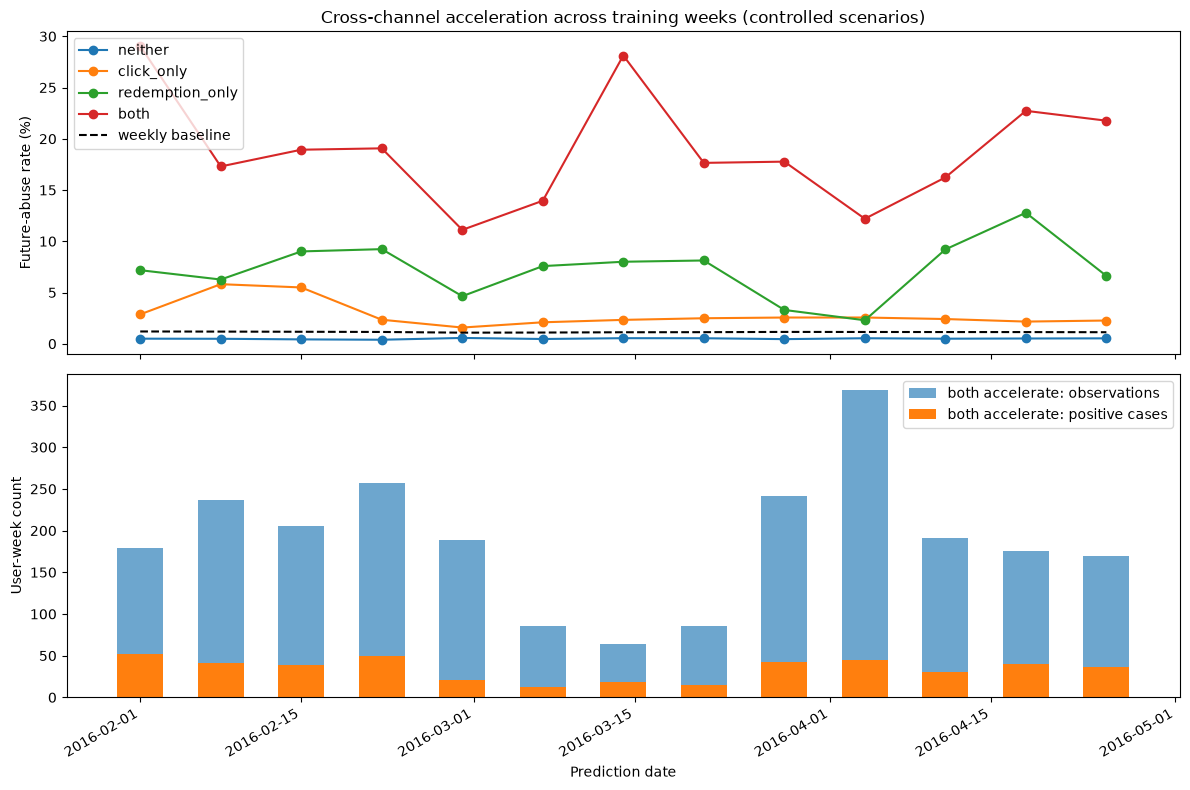

In [64]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for pattern in acceleration_order:
    axes[0].plot(
        weekly_cross_channel_rates.index,
        weekly_cross_channel_rates[pattern] * 100,
        marker="o", label=pattern,
    )
axes[0].plot(
    weekly_baseline.index, weekly_baseline["weekly_baseline_rate"] * 100,
    color="black", linestyle="--", label="weekly baseline",
)
axes[0].set_ylabel("Future-abuse rate (%)")
axes[0].set_title("Cross-channel acceleration across training weeks (controlled scenarios)")
axes[0].legend()
axes[1].bar(
    both_acceleration_weekly["prediction_date"],
    both_acceleration_weekly["observations"], width=4,
    label="both accelerate: observations", alpha=0.65,
)
axes[1].bar(
    both_acceleration_weekly["prediction_date"],
    both_acceleration_weekly["positive_cases"], width=4,
    label="both accelerate: positive cases",
)
axes[1].set_ylabel("User-week count")
axes[1].set_xlabel("Prediction date")
axes[1].legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Repeated-User Robustness: Cluster Bootstrap

Estimate 95% confidence intervals for combined-versus-neither acceleration risk using 2,000 user-level bootstrap samples from the training period.


In [65]:
# One row per user, containing their contributions across all training weeks.
cluster_input = cross_channel[
    ["user_id", "prediction_date", "abuse_next_7d", "acceleration_pattern"]
].copy()
assert not cluster_input.duplicated(["user_id", "prediction_date"]).any()
assert cluster_input["user_id"].notna().all()
assert cluster_input["abuse_next_7d"].isin([0, 1]).all()
assert cluster_input["acceleration_pattern"].isin(
    ["neither", "click_only", "redemption_only", "both"]
).all()
assert pd.to_datetime(cluster_input["prediction_date"]).between(
    pd.Timestamp(TRAIN_START), pd.Timestamp(TRAIN_END)
).all()

for group in ["both", "neither"]:
    cluster_input[f"{group}_n"] = (
        cluster_input["acceleration_pattern"].eq(group).astype(int)
    )
    cluster_input[f"{group}_positive"] = (
        cluster_input[f"{group}_n"] * cluster_input["abuse_next_7d"]
    )

cluster_columns = ["both_n", "both_positive", "neither_n", "neither_positive"]
user_totals = cluster_input.groupby("user_id")[cluster_columns].sum()
cluster_values = user_totals.to_numpy(dtype=float)
n_users = len(user_totals)
assert n_users > 1
assert (cluster_values.sum(axis=0)[[0, 2]] > 0).all()

# Resampling user rows preserves every selected user's weekly contributions.
rng = np.random.default_rng(42)
n_bootstrap = 2000
bootstrap_rates = np.full((n_bootstrap, 3), np.nan)
for b in range(n_bootstrap):
    sampled_users = rng.integers(0, n_users, size=n_users)
    both_n, both_positive, neither_n, neither_positive = (
        cluster_values[sampled_users].sum(axis=0)
    )
    if both_n > 0 and neither_n > 0:
        both_rate = both_positive / both_n
        neither_rate = neither_positive / neither_n
        bootstrap_rates[b] = [both_rate, neither_rate, both_rate - neither_rate]

valid = np.isfinite(bootstrap_rates).all(axis=1)
assert valid.sum() >= 0.99 * n_bootstrap, "Too many draws lack a comparison group."
both_n, both_positive, neither_n, neither_positive = cluster_values.sum(axis=0)
point_estimates = np.array([
    both_positive / both_n,
    neither_positive / neither_n,
    both_positive / both_n - neither_positive / neither_n,
])
intervals = np.quantile(bootstrap_rates[valid], [0.025, 0.975], axis=0)
cluster_bootstrap_summary = pd.DataFrame({
    "metric": ["Both rate (%)", "Neither rate (%)", "Risk gap (percentage points)"],
    "estimate": point_estimates * 100,
    "ci_95_lower": intervals[0] * 100,
    "ci_95_upper": intervals[1] * 100,
})
print(f"{len(cluster_input):,} user-weeks across {n_users:,} distinct users")
print(f"Users with multiple weeks: {cluster_input.groupby('user_id').size().gt(1).sum():,}")
print(f"Users contributing to both group: {user_totals['both_n'].gt(0).sum():,}")
print(f"Users contributing to neither group: {user_totals['neither_n'].gt(0).sum():,}")
print(f"Valid bootstrap draws: {valid.sum():,}/{n_bootstrap:,}")
display(cluster_bootstrap_summary.round(3))


483,431 user-weeks across 131,004 distinct users
Users with multiple weeks: 111,243
Users contributing to both group: 1,786
Users contributing to neither group: 123,422
Valid bootstrap draws: 2,000/2,000


,metric,estimate,ci_95_lower,ci_95_upper
0,Both rate (%),18.074,16.792,19.324
1,Neither rate (%),0.487,0.464,0.508
2,Risk gap (percentage points),17.588,16.303,18.836
